# PlantVillage Dataset — Train / Validation / Test Split

This notebook creates reproducible train, validation, and test splits from the validated PlantVillage color dataset.

The split is performed at the image level and is stratified by disease class to preserve the class distribution across all subsets.

### Split Strategy

- Training: 70%
- Validation: 15%
- Test: 15%
- Stratification: `class_id`
- Random seed: `42`
- Duplicate images are checked across splits
- Split metadata is saved as CSV files

The original images are not copied. The split files contain references to the existing image paths.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "plantvillage"

METADATA_PATH = DATA_DIR / "metadata.csv"

TRAIN_PATH = DATA_DIR / "train.csv"
VAL_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"

RANDOM_STATE = 49

In [3]:
metadata = pd.read_csv(METADATA_PATH)

print(f"Total images: {len(metadata):,}")
print(f"Total classes: {metadata['class_id'].nunique()}")
print()

metadata.head()

Total images: 54,304
Total classes: 38



,image_path,class_id,class_name,crop,condition
0,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
1,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
2,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
3,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab
4,PlantVillage-Dataset/raw/color/Apple___Apple_s...,0,Apple___Apple_scab,Apple,Apple_scab


In [4]:
required_columns = {
    "image_path",
    "class_id",
    "class_name",
    "crop",
    "condition",
}

missing_columns = required_columns - set(metadata.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print("All required columns are present.")

All required columns are present.


In [5]:
duplicate_paths = metadata["image_path"].duplicated().sum()

print(f"Duplicate image paths: {duplicate_paths}")

if duplicate_paths != 0:
    raise ValueError("Duplicate image paths found in metadata.")

print("No duplicate image paths found.")

Duplicate image paths: 0
No duplicate image paths found.


In [6]:
train_df, temp_df = train_test_split(
    metadata,
    test_size=0.3,
    stratify=metadata["class_id"],
    random_state=RANDOM_STATE,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["class_id"],
    random_state=RANDOM_STATE,
)

train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print(f"Train:      {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test:       {len(test_df):,}")

Train:      38,012
Validation: 8,146
Test:       8,146


In [7]:
total = len(metadata)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [
        len(train_df),
        len(val_df),
        len(test_df),
    ],
})

split_summary["Percentage"] = (
    split_summary["Images"] / total * 100
).round(2)

split_summary

,Split,Images,Percentage
0,Train,38012,70.0
1,Validation,8146,15.0
2,Test,8146,15.0


In [8]:
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

train_val_overlap = train_paths & val_paths
train_test_overlap = train_paths & test_paths
val_test_overlap = val_paths & test_paths

print(f"Train ↔ Validation overlap: {len(train_val_overlap)}")
print(f"Train ↔ Test overlap:       {len(train_test_overlap)}")
print(f"Validation ↔ Test overlap:  {len(val_test_overlap)}")

Train ↔ Validation overlap: 0
Train ↔ Test overlap:       0
Validation ↔ Test overlap:  0


In [9]:
if train_val_overlap or train_test_overlap or val_test_overlap:
    raise ValueError("Data leakage detected between dataset splits.")

print("No image-path overlap detected.")

No image-path overlap detected.


In [10]:
def class_distribution(df):
    return (
        df["class_id"]
        .value_counts(normalize=True)
        .sort_index()
    )


distribution = pd.DataFrame({
    "Train": class_distribution(train_df),
    "Validation": class_distribution(val_df),
    "Test": class_distribution(test_df),
})

distribution["Train_vs_Test_Difference"] = (
    distribution["Train"] - distribution["Test"]
).abs()

distribution.head()

,Train,Validation,Test,Train_vs_Test_Difference
class_id,,,,
0,0.011602,0.011662,0.011539,0.000062
1,0.011444,0.011417,0.011417,0.000027
2,0.005077,0.005033,0.005033,0.000044
3,0.030306,0.030199,0.030322,0.000015
4,0.027649,0.027621,0.027744,0.000095


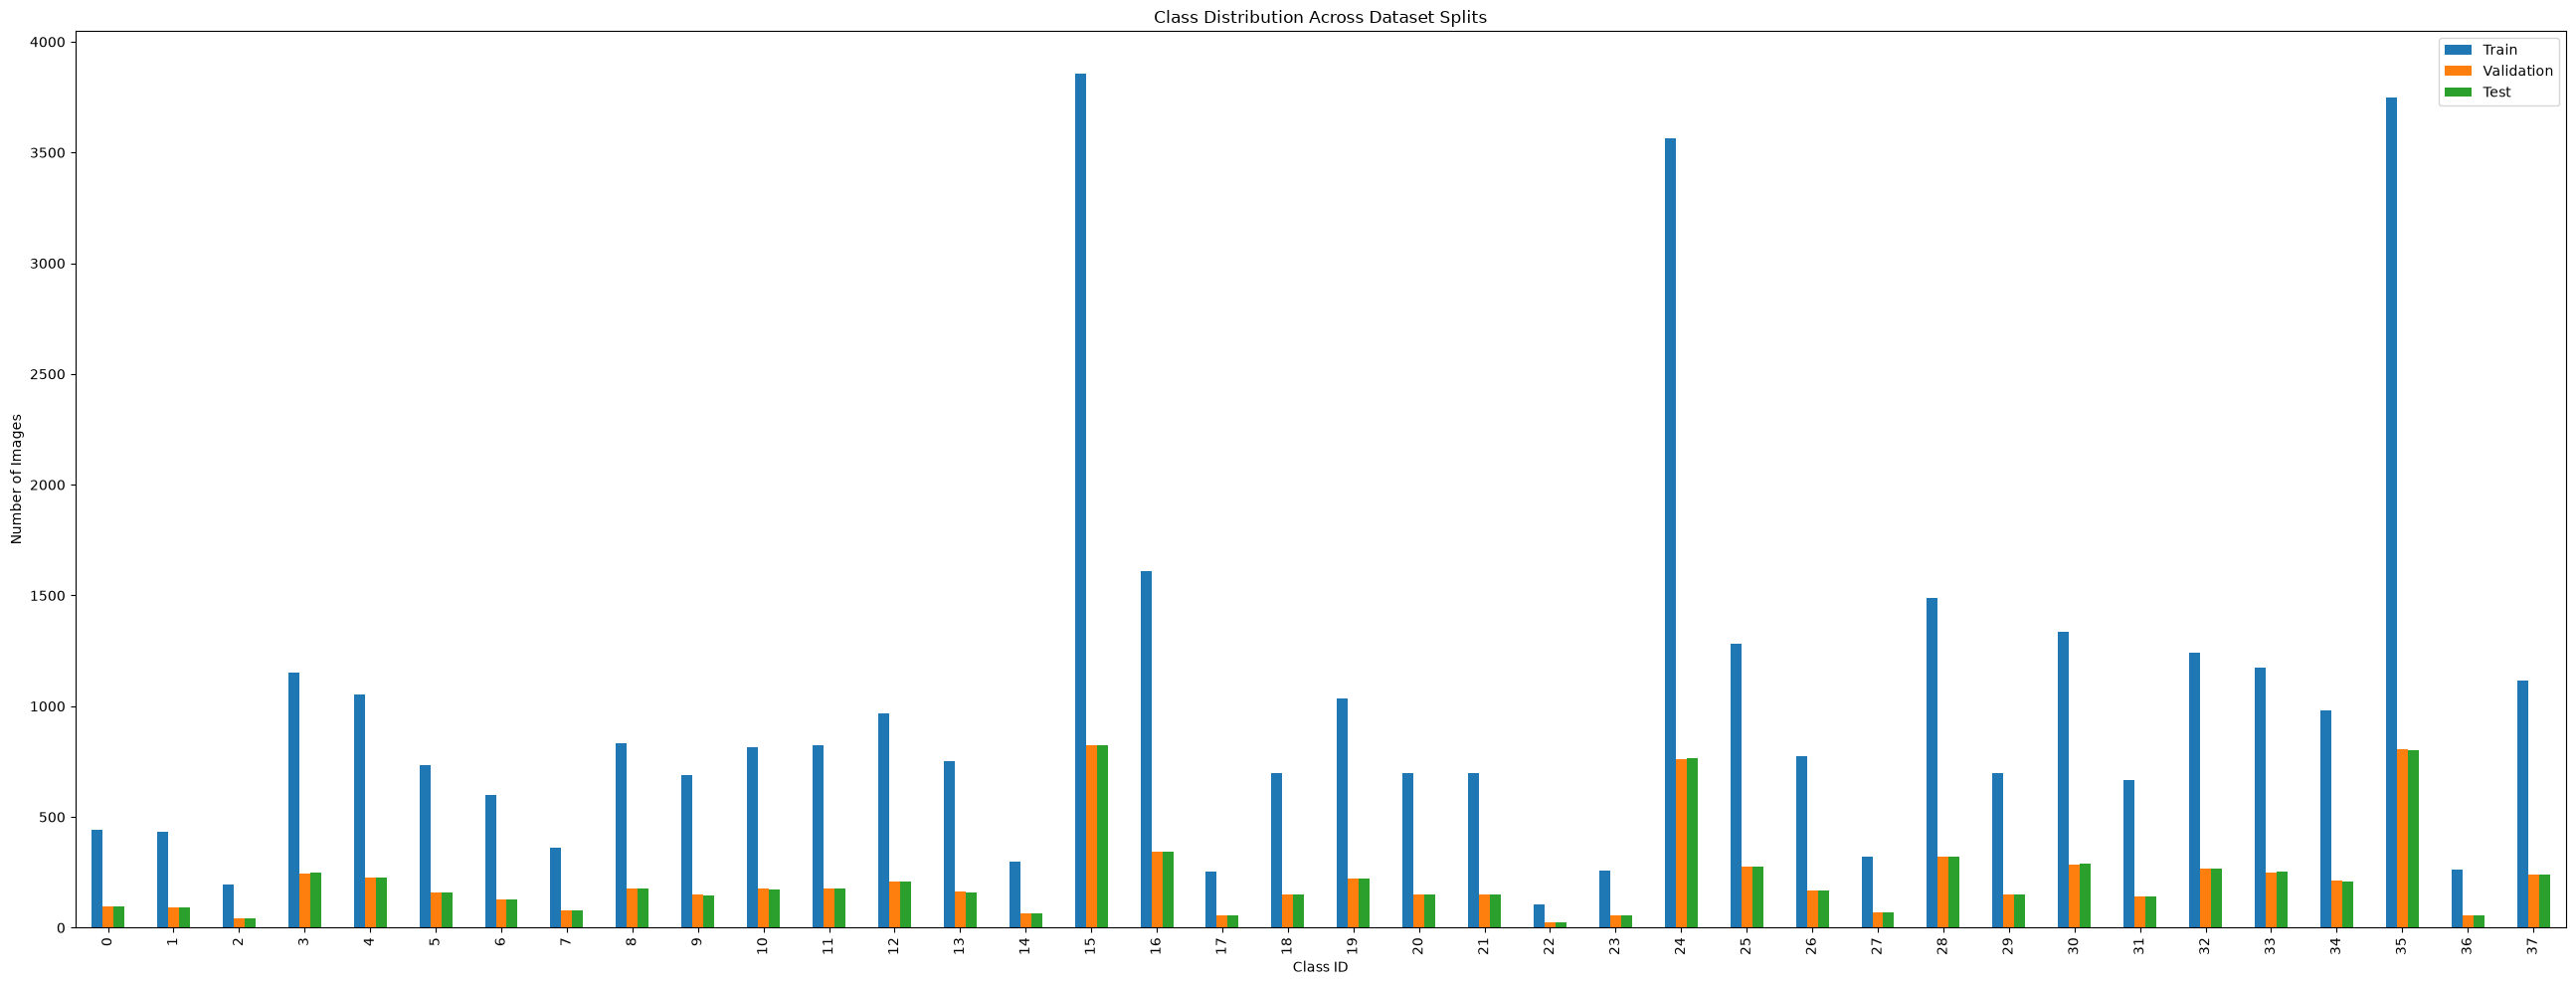

In [11]:
class_counts = pd.DataFrame({
    "Train": train_df["class_id"].value_counts().sort_index(),
    "Validation": val_df["class_id"].value_counts().sort_index(),
    "Test": test_df["class_id"].value_counts().sort_index(),
})

class_counts.plot(
    kind="bar",
    figsize=(26, 10),
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
train_classes = set(train_df["class_id"])
val_classes = set(val_df["class_id"])
test_classes = set(test_df["class_id"])

all_classes = set(metadata["class_id"])

print(f"Total classes:      {len(all_classes)}")
print(f"Training classes:   {len(train_classes)}")
print(f"Validation classes: {len(val_classes)}")
print(f"Test classes:       {len(test_classes)}")

if train_classes != all_classes:
    raise ValueError("Some classes are missing from the training set.")

if val_classes != all_classes:
    raise ValueError("Some classes are missing from the validation set.")

if test_classes != all_classes:
    raise ValueError("Some classes are missing from the test set.")

print("All 38 classes are present in every split.")

Total classes:      38
Training classes:   38
Validation classes: 38
Test classes:       38
All 38 classes are present in every split.


In [13]:
train_df.to_csv(TRAIN_PATH, index=False)
val_df.to_csv(VAL_PATH, index=False)
test_df.to_csv(TEST_PATH, index=False)

print(f"Train set saved to: {TRAIN_PATH}")
print(f"Validation set saved to: {VAL_PATH}")
print(f"Test set saved to: {TEST_PATH}")

Train set saved to: /Users/devangvamja/Documents/Projects/agrivision-ai/data/processed/plantvillage/train.csv
Validation set saved to: /Users/devangvamja/Documents/Projects/agrivision-ai/data/processed/plantvillage/validation.csv
Test set saved to: /Users/devangvamja/Documents/Projects/agrivision-ai/data/processed/plantvillage/test.csv


In [14]:
saved_train = pd.read_csv(TRAIN_PATH)
saved_val = pd.read_csv(VAL_PATH)
saved_test = pd.read_csv(TEST_PATH)

print("Final split verification")
print("-" * 35)
print(f"Train:      {len(saved_train):,}")
print(f"Validation: {len(saved_val):,}")
print(f"Test:       {len(saved_test):,}")
print(f"Total:      {len(saved_train) + len(saved_val) + len(saved_test):,}")

if len(saved_train) + len(saved_val) + len(saved_test) != len(metadata):
    raise ValueError("Saved split sizes do not match the original dataset.")

print("\nDataset split completed successfully.")

Final split verification
-----------------------------------
Train:      38,012
Validation: 8,146
Test:       8,146
Total:      54,304

Dataset split completed successfully.


## Dataset Split Findings

The validated PlantVillage color dataset containing 54,304 images across 38 classes was divided into training, validation, and test sets using a stratified 70/15/15 split.

Stratification was performed using the disease class so that each subset maintains a distribution similar to the original dataset. This is particularly important because the EDA identified substantial class imbalance, with the largest class containing 5,507 images and the smallest containing 152 images.

The split was also checked for image-path overlap to prevent data leakage between training, validation, and test sets. All 38 classes were verified to be present in each subset.

The original image files were not duplicated. Instead, the split metadata was saved as CSV files containing references to the existing images.

### Result

The dataset is now ready for model development.

The next stage is to establish a **baseline CNN model** using the training set, while using the validation set for model selection and keeping the test set isolated for final evaluation.